# M07 — Baselines and Model Comparison

M06 ke prepared data se **separate bus aur rail** classification experiments. 2022–September 2023 training aur 2024 validation use hoti hai. 2025 ko is notebook mein score ya model choose karne ke liye use nahi karte.

Outputs 90-day publication-delay **assumption** par historical simulation hain. CTA ki real delay aur historical revisions verify nahi hue. M05 ne poora period visualize kiya tha, isliye 2025 perfectly untouched holdout nahi hai.


## 1. Libraries aur M06 files

M06 pehle run honi chahiye. `scikit-learn` required hai. Notebook project root, `backend` ya `backend/notebooks` se run karo.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

if Path("backend/data/processed").is_dir():
    data_folder = Path("backend/data/processed")
elif Path("data/processed").is_dir():
    data_folder = Path("data/processed")
else:
    data_folder = Path("../data/processed")

print("M06 data folder:", data_folder.resolve())


M06 data folder: C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\transit-ridership\backend\data\processed


## 2. Inputs aur chronological splits

`entity_id` category hai; calendar fields aur 91-day old rides features hain. Training-only thresholds se `relative_lag_91` bhi banate hain: `(91-day rides − lower) / (upper − lower)`. Is se model ko us entity ki historical range ka context milta hai. `target`, `date` aur `split` model inputs nahi hain.


In [2]:
feature_columns = ["entity_id", "weekday", "month", "day_of_month", "is_weekend", "lag_91_rides", "relative_lag_91"]
classes = ["Low", "Normal", "High"]
data = {}
thresholds = {}

for name in ["bus", "rail"]:
    df = pd.read_csv(data_folder / f"{name}_model_data.csv", dtype={"entity_id": str}, parse_dates=["date"])
    thresholds[name] = pd.read_csv(data_folder / f"{name}_train_thresholds.csv", dtype={"entity_id": str})
    # M06 ke frozen training thresholds sirf purani rides ke context ke liye hain.
    df = df.loc[df["split"].isin(["train", "validation"])].copy()
    df = df.merge(thresholds[name][["entity_id", "lower", "upper"]], on="entity_id", how="left", validate="many_to_one")
    if df[["lower", "upper"]].isna().any().any() or (df["upper"] <= df["lower"]).any():
        raise ValueError(f"{name}: training thresholds missing ya invalid hain; M06 check karo.")
    df["relative_lag_91"] = (df["lag_91_rides"] - df["lower"]) / (df["upper"] - df["lower"])
    train = df.loc[df["split"] == "train"].copy()
    validation = df.loc[df["split"] == "validation"].copy().reset_index(drop=True)
    if train.empty or validation.empty:
        raise ValueError(f"{name}: training/validation empty hai; M06 files check karo.")
    if train["date"].max() > pd.Timestamp("2023-09-30") or not validation["date"].between("2024-01-01", "2024-12-31").all():
        raise ValueError(f"{name}: dates M06 split se match nahi kartin.")
    data[name] = {"train": train, "validation": validation}
    print(f"{name}: train = {len(train):,} | validation = {len(validation):,}")
    print("Training class counts:")
    print(train["target"].value_counts().reindex(classes, fill_value=0))


bus: train = 61,832 | validation = 41,294
Training class counts:
target
Low       18578
Normal    20144
High      23110
Name: count, dtype: int64
rail: train = 77,127 | validation = 51,606
Training class counts:
target
Low       22652
Normal    25039
High      29436
Name: count, dtype: int64


## 3. Models aur baselines

1. **Majority:** training mein jo class sab se common ho, wahi predict kare.
2. **91-day rule:** 91 din purani ridership ko training-period thresholds se classify kare. Ye simple history-based baseline hai.
3. **Logistic Regression:** class-weighted model; class imbalance handle karne ki ek koshish.
4. **Decision Tree:** depth 8 aur depth 14 compare karte hain; ye small tuning experiment hai.

Route/station IDs one-hot encode aur numerical inputs scale honge. Pipeline in transformations ko **sirf training data par fit** karti hai. Validation ka target fit mein use nahi hota.


In [3]:
predictions = {}
trained_models = {}

for name, parts in data.items():
    train, validation = parts["train"], parts["validation"]
    X_train, y_train = train[feature_columns], train["target"]
    X_val = validation[feature_columns]
    predictions[name] = {}
    trained_models[name] = {}

    majority = DummyClassifier(strategy="most_frequent")
    majority.fit(X_train, y_train)
    predictions[name]["Majority baseline"] = majority.predict(X_val)

    history = validation[["entity_id", "lag_91_rides"]].merge(
        thresholds[name][["entity_id", "lower", "upper"]], on="entity_id", how="left", validate="many_to_one")
    if history[["lower", "upper"]].isna().any().any():
        raise ValueError(f"{name}: validation ke liye training thresholds missing hain.")
    predictions[name]["91-day baseline"] = np.select(
        [history["lag_91_rides"] <= history["lower"], history["lag_91_rides"] <= history["upper"]],
        ["Low", "Normal"], default="High")

    numerical = ["weekday", "month", "day_of_month", "is_weekend", "lag_91_rides", "relative_lag_91"]
    algorithms = {
        "Logistic Regression (balanced)": LogisticRegression(max_iter=400, class_weight="balanced", random_state=42),
        "Decision Tree (depth 8)": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42),
        "Decision Tree (depth 14)": DecisionTreeClassifier(max_depth=14, min_samples_leaf=50, random_state=42),
    }
    for label, algorithm in algorithms.items():
        preprocessing = ColumnTransformer([
            ("entity", OneHotEncoder(handle_unknown="ignore"), ["entity_id"]),
            ("numeric", StandardScaler(), numerical),
        ])
        pipeline = Pipeline([("prepare", preprocessing), ("model", algorithm)])
        print(f"Training {name}: {label} ...")
        pipeline.fit(X_train, y_train)
        trained_models[name][label] = pipeline
        predictions[name][label] = pipeline.predict(X_val)
    print(f"{name}: training complete")


Training bus: Logistic Regression (balanced) ...
Training bus: Decision Tree (depth 8) ...
Training bus: Decision Tree (depth 14) ...
bus: training complete
Training rail: Logistic Regression (balanced) ...
Training rail: Decision Tree (depth 8) ...
Training rail: Decision Tree (depth 14) ...
rail: training complete


## 4. Validation comparison

**Accuracy** overall correct predictions hai. **Macro F1** teen classes ko equal importance deta hai. **Balanced accuracy** per-class recall ka average hai. High class common ho sakti hai, isliye sirf accuracy se model choose nahi karenge. Best overall result baselines mein bhi ho sakta hai.


In [4]:
comparisons = {}
for name, choices in predictions.items():
    y_val = data[name]["validation"]["target"]
    rows = []
    for label, predicted in choices.items():
        rows.append({"Method": label,
                     "Accuracy": accuracy_score(y_val, predicted),
                     "Balanced accuracy": balanced_accuracy_score(y_val, predicted),
                     "Macro F1": f1_score(y_val, predicted, labels=classes, average="macro", zero_division=0)})
    comparisons[name] = pd.DataFrame(rows).set_index("Method").sort_values("Macro F1", ascending=False)
    print(f"\n{name.upper()} — 2024 validation")
    display(comparisons[name].round(3))



BUS — 2024 validation


,Accuracy,Balanced accuracy,Macro F1
Method,,,
Decision Tree (depth 8),0.688,0.641,0.625
Decision Tree (depth 14),0.638,0.632,0.603
91-day baseline,0.672,0.588,0.586
Logistic Regression (balanced),0.678,0.570,0.549
Majority baseline,0.615,0.333,0.254



RAIL — 2024 validation


,Accuracy,Balanced accuracy,Macro F1
Method,,,
Decision Tree (depth 8),0.698,0.661,0.643
Decision Tree (depth 14),0.675,0.656,0.636
Logistic Regression (balanced),0.687,0.624,0.615
91-day baseline,0.667,0.607,0.605
Majority baseline,0.555,0.333,0.238


## 5. Class-wise results aur confusion matrix

Validation macro F1 par best method choose hota hai, chahe woh baseline hi kyun na ho. Report mein har class ki precision, recall aur F1 dekho. Confusion matrix mein **rows actual** aur **columns predicted** hain.



BUS — best validation method: Decision Tree (depth 8)
              precision    recall  f1-score   support

         Low       0.68      0.78      0.72      8137
      Normal       0.33      0.40      0.36      7753
        High       0.84      0.75      0.79     25404

    accuracy                           0.69     41294
   macro avg       0.62      0.64      0.63     41294
weighted avg       0.71      0.69      0.70     41294



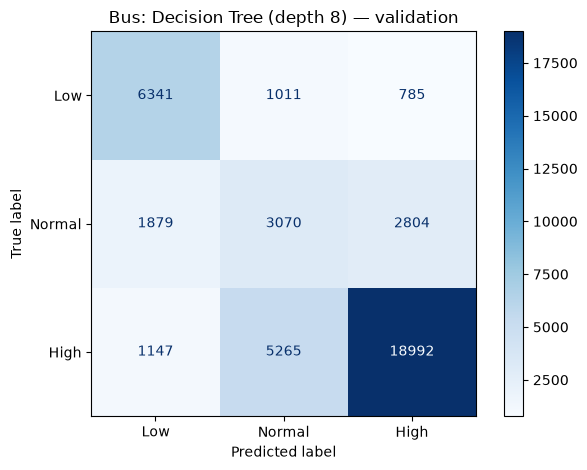


RAIL — best validation method: Decision Tree (depth 8)
              precision    recall  f1-score   support

         Low       0.67      0.84      0.74     12381
      Normal       0.38      0.39      0.39     10574
        High       0.85      0.75      0.80     28651

    accuracy                           0.70     51606
   macro avg       0.63      0.66      0.64     51606
weighted avg       0.71      0.70      0.70     51606



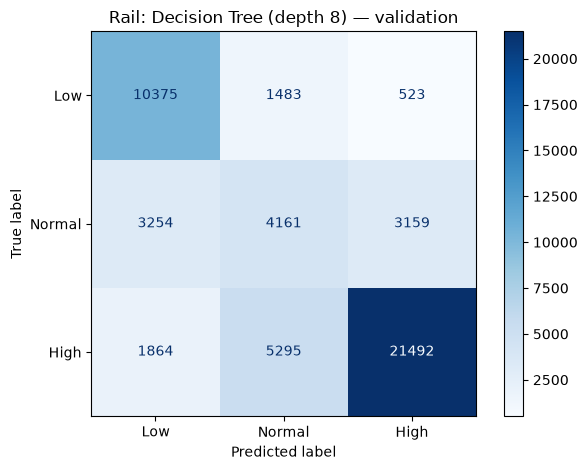

In [5]:
for name, comparison in comparisons.items():
    best = comparison.index[0]
    y_val = data[name]["validation"]["target"]
    predicted = predictions[name][best]
    print(f"\n{name.upper()} — best validation method: {best}")
    print(classification_report(y_val, predicted, labels=classes, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_val, predicted, labels=classes, cmap="Blues", values_format="d")
    plt.title(f"{name.title()}: {best} — validation")
    plt.tight_layout()
    plt.show()


## 6. Conclusion aur limitations

- Best ML model ko dono baselines se compare karo. Agar baseline better ho to honestly report karo; improvement guaranteed nahi.
- Depth 8 aur 14 ka comparison limited tuning hai. Relative-history feature ko bhi 2024 validation results dekh kar add kiya gaya; isliye best validation score optimistic ho sakta hai.
- Class-wise scores aur exclusion of entities/missing lag bhi interpret karo. Labels relative historical demand hain, overcrowding ya live operations nahi.
- 2025 ka data is notebook mein score nahi hota. M05 mein dekhne ki wajah se woh perfectly untouched test nahi hoga; honest limitation document karo.
- Trained models sirf notebook memory mein hain; koi model file save nahi hoti. Encoding, scaling aur model ko reproducibly train karne aur final evaluation ka step next module mein hoga.
